<a href="https://colab.research.google.com/github/atempvisit/learning-deep_learning/blob/main/Module_16_From_ANN_Implementation_to_GPU_Training_with_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [89]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [109]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [90]:
torch.manual_seed(42)

In [91]:
df = pd.read_csv('fmnist_small.csv')
df

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1,0,0,0,0,0,0,0,0,0,...,69,12,0,0,0,0,0,0,0,0
5996,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5997,8,0,0,0,0,0,0,0,0,0,...,39,47,2,0,0,29,0,0,0,0
5998,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


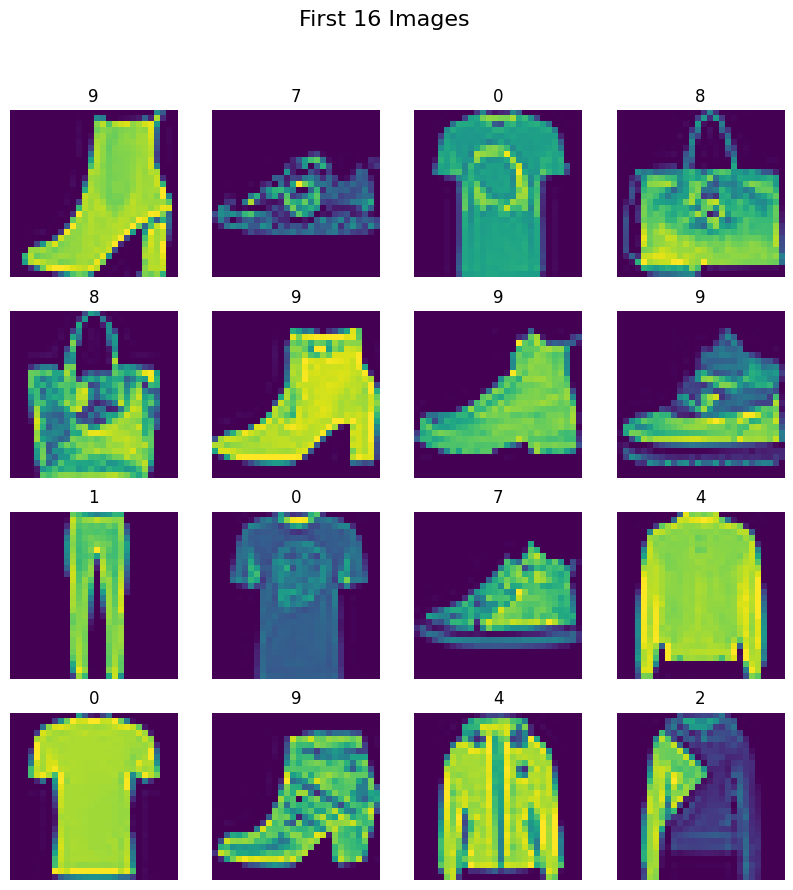

In [92]:
fig, axes = plt.subplots(4,4, figsize=(10, 10))
fig.suptitle('First 16 Images', fontsize = 16)

for i, ax in enumerate(axes.flatten()):
    img = df.iloc[i, 1:].values.reshape(28, 28)
    ax.imshow(img)
    ax.axis('off')

    ax.set_title(df.iloc[i, 0])
plt.show()

In [93]:
len(df.columns)

785

In [94]:
len(df['label'].unique())

10

In [95]:
len(df.iloc[:, 1:])

6000

In [96]:
# train test split

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Scaling

In [97]:
X_train = X_train/255.0
X_test = X_test/255.0

Dataset

In [98]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]

In [99]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)
#

Loader

In [100]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Define NN Class

In [101]:
class MyNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()

    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )

  def forward(self, x):
    return self.model(x)

Instantiate Model

In [102]:
epochs = 100
learning_rate = 0.1

In [110]:
model = MyNN(X_train.shape[1])

# model.to(device) # In case of GPU computation

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [104]:
criterion = nn.CrossEntropyLoss()

In [105]:
model.parameters()

<generator object Module.parameters at 0x78eaf6bbfbc0>

In [106]:
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

Training Loop

In [107]:
for epoch in range(epochs):
  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move batch_features, batch_labels to GPU
    # batch_features = batch_features.to(device)
    # batch_labels = batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # loss function
    loss = criterion(outputs, batch_labels)

    # backward pass
    optimizer.zero_grad()
    loss.backward()

    # update
    optimizer.step()

    total_epoch_loss += loss.item()

  # Print average loss per batch for this epoch if desired
  # print(f'Epoch {epoch+1}/{epochs}, Loss: {total_loss / len(train_loader)}')

# Calculate and print the true average loss per batch in the final epoch
avg_loss = total_epoch_loss / len(train_loader)
print(f'Average Loss: {avg_loss}')

Average Loss: 0.008310633393703028


Evaluation

In [108]:
model.eval()

total = 0
correct = 0


with torch.no_grad():
  for batch_features, batch_labels in test_loader:

    # move batch_features, batch_labels to GPU
    # batch_features = batch_features.to(device)
    # batch_labels = batch_labels.to(device)


    outputs = model(batch_features)
    # print(f"outputs: {outputs}")

    _, predicted = torch.max(outputs, 1)
    # print(f"predicted: {predicted}")

    total += batch_labels.shape[0]
    correct += (predicted == batch_labels).sum().item()


print(f"Total: {total}")
print(f"Correct: {correct}")
print(f"Accuracy: {correct/total}")

Total: 1200
Correct: 999
Accuracy: 0.8325
